# Workshop-2 - Data profiling (Spotify + Grammy)

**Purpose.** Profiling *discovers* what the data look like and what could go wrong (Topic 2.1). It does **not** clean data and it
does **not** create rules automatically: every finding below is interpreted and then linked to a quality rule (`src/quality_rules.py`)
or to a documented transformation (`docs/transformation_decisions.md`).

Three profiling types (class 2.1): **structural** (schema, types, row counts), **content** (nulls, ranges, distributions),
**relationship** (keys, duplicates, cross-source consistency).

Analytical requirements that guide what we inspect: **AR1** popularity of Grammy-recognised tracks vs genre baseline by decade,
**AR2** audio profile by decade, **AR3** genres / Grammy families that concentrate recognised tracks.

In [1]:
import sys, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import transform as T

EVID = ROOT / "docs" / "evidence" / "profiling"
EVID.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

sp = pd.read_csv(ROOT / "data/raw/spotify_dataset.csv", low_memory=False)
gr = pd.read_csv(ROOT / "data/raw/the_grammy_awards.csv")
print("Spotify:", sp.shape, "| Grammy:", gr.shape)

Spotify: (114000, 21) | Grammy: (4810, 10)


## 1. Structural profiling

In [2]:
def structure(df, name):
    t = pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(), "distinct": df.nunique(dropna=True)})
    t.insert(0, "dataset", name); return t
struct = pd.concat([structure(sp, "spotify"), structure(gr, "grammy")])
struct.to_csv(EVID / "structure.csv")
display(struct)

,dataset,dtype,non_null,distinct
Unnamed: 0,spotify,int64,114000,114000
track_id,spotify,object,114000,89741
artists,spotify,object,113999,31437
album_name,spotify,object,113999,46589
track_name,spotify,object,113999,73608
popularity,spotify,int64,114000,101
duration_ms,spotify,int64,114000,50697
explicit,spotify,bool,114000,2
danceability,spotify,float64,114000,1174
energy,spotify,float64,114000,2083


**Reading.** Spotify has an anonymous export index (`Unnamed: 0`) with no business meaning. `artists` packs several artists into one string
separated by `;`. Grammy `winner` is boolean, `year` integer, dates are ISO text.

## 2. Completeness (content profiling)

In [3]:
def nulls(df, name):
    t = pd.DataFrame({"missing": df.isna().sum(), "missing_pct": (df.isna().mean() * 100).round(3)})
    t.insert(0, "dataset", name); return t[t.missing > 0]
miss = pd.concat([nulls(sp, "spotify"), nulls(gr, "grammy")])
miss.to_csv(EVID / "missingness.csv"); display(miss)

,dataset,missing,missing_pct
artists,spotify,1,0.001
album_name,spotify,1,0.001
track_name,spotify,1,0.001
nominee,grammy,6,0.125
artist,grammy,1840,38.254
workers,grammy,2190,45.530
img,grammy,1367,28.420


In [4]:
# WHY is Grammy.artist missing? -> structural, by category type
gr["_cat"] = gr.category.str.lower().str.strip()
gr["_type"] = gr._cat.map(T.classify_nominee_type)
why = gr.groupby("_type").agg(rows=("artist", "size"), artist_missing_pct=("artist", lambda s: round(100 * s.isna().mean(), 1)))
display(why)
print("Song Of The Year rows without artist:", int(gr[gr._cat == "song of the year"].artist.isna().sum()), "of", int((gr._cat == "song of the year").sum()))
print("Nominee missing:", gr[gr.nominee.isna()].category.unique().tolist())
why.to_csv(EVID / "grammy_artist_missing_by_type.csv")

,rows,artist_missing_pct
_type,,
album,1610,25.4
person,167,99.4
recording_or_work,3033,41.7


Song Of The Year rows without artist: 70 of 70
Nominee missing: ['Remixer of the Year, Non-Classical', 'Remixer Of The Year, Non-Classical', 'Remixer Of The Year, Non-classical', 'Best New Country & Western Artist', 'Best New Country & Western Artist Of 1964']


**Interpretation.** The 38% missing `artist` is **not random**: it is concentrated in categories that honour songwriters, composers,
producers or technical credits (Song Of The Year 70/70, Opera Recording, Album Notes, Instrumental Composition, Country Song...). Person categories
are 99% missing and recordings 42%. Missing `artist` cannot be "fixed" without inventing data; we (a) tolerate it with a *warning* threshold
(rule **GR-06**) and (b) recover it only for *matching* from other rows of the same year+title (documented transformation). The 6 missing `nominee`
rows (4 "Remixer of the Year", 2 "Best New Country & Western Artist") are unidentifiable records -> dropped in transformation, rule **GR-05**.
Spotify has exactly **one** row with no name/artist/album -> rule **SP-08**.

## 3. Validity - ranges and impossible values

In [5]:
num = ["popularity","duration_ms","danceability","energy","valence","acousticness","loudness","tempo","speechiness","liveness","instrumentalness"]
rng = sp[num].describe().T[["min","25%","50%","75%","max"]]
rng["zeros"] = (sp[num] == 0).sum()
display(rng); rng.to_csv(EVID / "spotify_numeric_ranges.csv")
print("tempo == 0:", int((sp.tempo == 0).sum()), "| duration_ms == 0:", int((sp.duration_ms == 0).sum()),
      "| popularity == 0:", int((sp.popularity == 0).sum()), f"({(sp.popularity == 0).mean():.1%})")
print("time_signature values:", sp.time_signature.value_counts().sort_index().to_dict())
print("Grammy year range:", gr.year.min(), "-", gr.year.max(), "| distinct years:", gr.year.nunique())

,min,25%,50%,75%,max,zeros
popularity,0.000,17.00000,35.000000,50.0000,100.000,16020
duration_ms,0.000,174066.00000,212906.000000,261506.0000,5237295.000,1
danceability,0.000,0.45600,0.580000,0.6950,0.985,157
energy,0.000,0.47200,0.685000,0.8540,1.000,1
valence,0.000,0.26000,0.464000,0.6830,0.995,176
acousticness,0.000,0.01690,0.169000,0.5980,0.996,39
loudness,-49.531,-10.01300,-7.004000,-5.0030,4.532,0
tempo,0.000,99.21875,122.017000,140.0710,243.372,157
speechiness,0.000,0.03590,0.048900,0.0845,0.965,157
liveness,0.000,0.09800,0.132000,0.2730,1.000,2


tempo == 0: 157 | duration_ms == 0: 1 | popularity == 0: 16020 (14.1%)
time_signature values: {0: 163, 1: 973, 3: 9195, 4: 101843, 5: 1826}
Grammy year range: 1958 - 2019 | distinct years: 62


**Interpretation.**
* `popularity` 0-100, `danceability/energy/valence/acousticness` 0-1 and `loudness` -49.5..+4.5: **all inside documented scales** -> strict rules
  **SP-05/SP-06** (critical) and tolerant **SP-07**. The rules were written from the *scale documentation*, not from today's min/max.
* **157 tracks with tempo = 0** are physically impossible, and the profile shows the *same 157 rows* also have danceability = speechiness =
  time_signature = 0: one failure pattern of Spotify's audio analysis (mostly sparse ambient / classical tracks), not 157 real zeros. -> rule **SP-10**
  (warning) + transformation sets tempo, danceability and valence of those rows to NULL (never imputed). The single duration = 0 row is the record that has no name.
* 14% of tracks have popularity 0. That is a *valid* value of the scale (no recent plays) -> **not** treated as an error; "suspicious does not mean wrong".

## 4. Uniqueness and grain

In [6]:
rep_ids = int(sp.track_id.duplicated().sum()); pair_dups = int(sp.duplicated(["track_id","track_genre"]).sum())
print(f"Spotify rows: {len(sp):,} | distinct track_id: {sp.track_id.nunique():,} | repeated track_id rows: {rep_ids:,}")
print(f"Repeated (track_id, track_genre) pairs: {pair_dups} -> rows involved: {int(sp.duplicated(['track_id','track_genre'], keep=False).sum())}")
d = sp.groupby("track_id").agg(n=("track_id", "size"), pops=("popularity", "nunique"), genres=("track_genre", "nunique"))
print("track_ids with >1 row:", int((d.n > 1).sum()), "| with different popularity across rows:", int((d.pops > 1).sum()))
key = ["year","category","nominee","artist"]
print("Grammy duplicated (year, category, nominee, artist):", int(gr.duplicated(key).sum()))

Spotify rows: 114,000 | distinct track_id: 89,741 | repeated track_id rows: 24,259
Repeated (track_id, track_genre) pairs: 450 -> rows involved: 894


track_ids with >1 row: 16641 | with different popularity across rows: 720
Grammy duplicated (year, category, nominee, artist): 0


**Interpretation (grain).** The Spotify source grain is **track x genre** (a song listed in several genres appears several times), *not* one row per track.
Repeated `track_id` is therefore expected; only exact repeats of `(track_id, genre)` are duplicates (**SP-04**, warning). Counting rows as tracks
would over-weight multi-genre songs -> transformation collapses to **one row per track**, keeping the highest-popularity copy (it also defines the *primary genre*).
Grammy has no duplicated business key (**GR-09**).

## 5. Consistency of categories and the Grammy `winner` flag

In [7]:
low = gr.category.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
print("category spellings:", gr.category.nunique(), "-> after case/space folding:", low.nunique())
print(gr.winner.value_counts(dropna=False).to_dict())
per = gr.groupby(["year","category"]).size().groupby("year").mean().round(2)
display(per.tail(6).to_frame("avg rows per category"))

category spellings: 638 -> after case/space folding: 629
{True: 4810}


,avg rows per category
year,
2014,1.00
2015,1.01
2016,1.01
2017,1.02
2018,1.02
2019,5.15


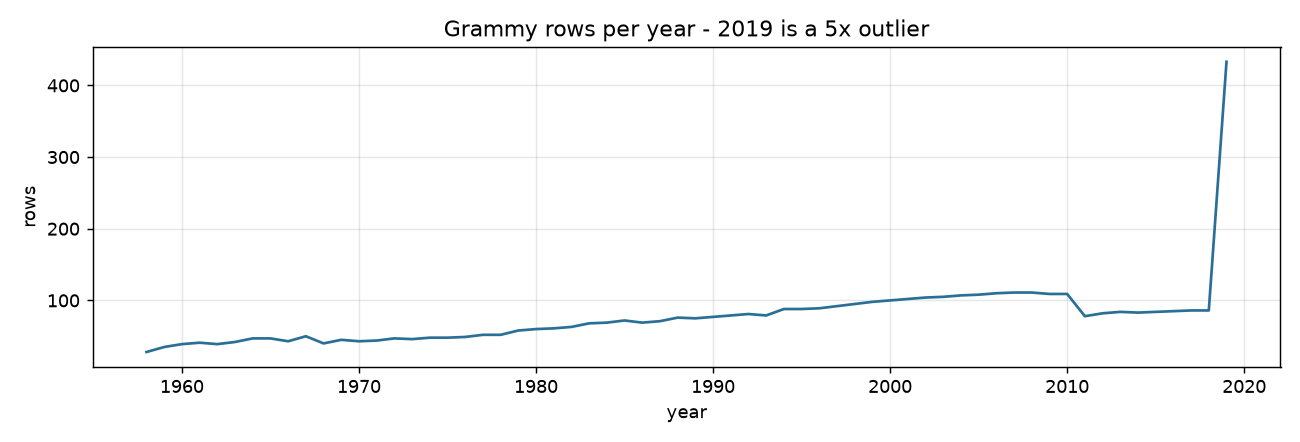

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
gr.groupby("year").size().plot(ax=ax, color="#2a6f97")
ax.set_title("Grammy rows per year - 2019 is a 5x outlier"); ax.set_ylabel("rows"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(EVID / "grammy_rows_per_year.png", dpi=130); plt.close(fig)
from IPython.display import Image; display(Image(EVID / "grammy_rows_per_year.png"))

**Interpretation - the most important finding.** `winner = True` in **100%** of rows, yet 2019 contains ~5 rows per category (all nominees)
while 1958-2018 contain ~1 (winners only). The flag cannot separate winners from nominees and the **row grain differs by year**.
Decisions: (1) **no requirement uses `winner`**; rows are "Grammy recognitions"; (2) `dim_year.coverage_type` = `winners_only` / `all_nominees`
makes the difference explicit; (3) rule **GR-08** (warning) *documents* the limitation and is **expected to fail** on this batch, proving the
"warning -> continue" policy. 638 category spellings collapse to 626 (case/spacing variants) -> harmonised in transformation.

In [9]:
# whitespace consistency (feeds transformation T2)
for df, name, cols in [(sp, "spotify", ["artists","album_name","track_name","track_genre"]), (gr, "grammy", ["category","nominee","artist","title"])]:
    for c in cols:
        v = df[c].dropna()
        print(f"{name}.{c}: leading/trailing spaces={int((v != v.str.strip()).sum())} | double spaces={int(v.str.contains('  ').sum())}")

spotify.artists: leading/trailing spaces=8 | double spaces=0
spotify.album_name: leading/trailing spaces=0 | double spaces=0
spotify.track_name: leading/trailing spaces=0 | double spaces=0
spotify.track_genre: leading/trailing spaces=0 | double spaces=0
grammy.category: leading/trailing spaces=0 | double spaces=2
grammy.nominee: leading/trailing spaces=0 | double spaces=7
grammy.artist: leading/trailing spaces=0 | double spaces=1
grammy.title: leading/trailing spaces=0 | double spaces=4810


## 6. Relationship profiling - can the two sources be integrated?

In [10]:
sp2 = sp.dropna(subset=["track_name","artists"]).copy()
sp2["title_key"] = sp2.track_name.map(T.norm_title)
gr2 = gr.dropna(subset=["nominee"]).copy()
gr2["title_key"] = gr2.nominee.map(T.norm_title)
shared = set(sp2.title_key.dropna()) & set(gr2.title_key.dropna())
print("distinct normalised titles in common:", len(shared), "| Grammy rows whose title exists in Spotify:", int(gr2.title_key.isin(shared).sum()))
print("There is NO shared key -> integration needs title + artist matching (fuzzy by normalisation, deterministic).")

distinct normalised titles in common: 866 | Grammy rows whose title exists in Spotify: 1140
There is NO shared key -> integration needs title + artist matching (fuzzy by normalisation, deterministic).


In [11]:
# Run the real transformation logic on the raw files to quantify integration quality (same code as the pipeline)
import tempfile, hashlib, json
tmp = Path(tempfile.mkdtemp())
(tmp / "raw").mkdir()
sp.to_csv(tmp / "raw/spotify_raw.csv", index=False)
g_in = gr.drop(columns=[c for c in gr.columns if c.startswith("_")]).copy(); g_in.insert(0, "row_id", range(1, len(g_in) + 1))
g_in.to_csv(tmp / "raw/grammys_raw.csv", index=False)
sm = {"raw_path": str(tmp / "raw/spotify_raw.csv"), "source_sha256": "profiling"}
gm = {"raw_path": str(tmp / "raw/grammys_raw.csv"), "source_sha256": "profiling"}
meta = T.transform_and_integrate(sm, gm, tmp)
rec = json.load(open(meta["reconciliation_path"]))
status = pd.Series(rec["integration"]["status_counts"]).rename("nominations").to_frame()
status["pct"] = (100 * status.nominations / status.nominations.sum()).round(2)
display(status); status.to_csv(EVID / "integration_status.csv")
print("matched with >1 Spotify candidate:", rec["integration"]["matched_with_more_than_one_candidate"],
      "| distinct tracks matched:", rec["integration"]["distinct_tracks_matched"])

,nominations,pct
not_matchable_album_or_person,1773,36.91
unmatched_no_title_candidate,1268,26.39
not_matchable_missing_artist,1047,21.79
unmatched_artist_mismatch,412,8.58
matched,304,6.33


matched with >1 Spotify candidate: 115 | distinct tracks matched: 222


In [12]:
fact = pd.read_csv(Path(meta["prepared_dir"]) / "fact_grammy_nomination.csv")
fact["decade"] = (fact.year_key // 10) * 10
by_dec = fact.groupby("decade").agg(nominations=("nomination_key", "size"), matched=("spotify_matched", "sum"))
by_dec["match_rate_pct"] = (100 * by_dec.matched / by_dec.nominations).round(1)
display(by_dec); by_dec.to_csv(EVID / "match_rate_by_decade.csv")
ax = by_dec.match_rate_pct.plot(kind="bar", figsize=(8, 3), color="#52b788"); ax.set_ylabel("% matched"); ax.set_title("Integration coverage by decade")
plt.tight_layout(); plt.savefig(EVID / "match_rate_by_decade.png", dpi=130); plt.close()

,nominations,matched,match_rate_pct
decade,,,
1950,63,5,7.9
1960,431,20,4.6
1970,487,30,6.2
1980,684,42,6.1
1990,863,59,6.8
2000,1066,58,5.4
2010,1210,90,7.4


**Interpretation.** Only ~6% of Grammy records can be linked to a Spotify track. The rest are not matchable on purpose (albums, people,
no performing artist) or simply absent from the 114k-track catalogue. That is an **honest property of the data**, so the KPIs are
computed on matched recordings only and the **match coverage itself is a KPI**. Match counts per decade (5 in the 1950s ... 90 in the 2010s)
are small in the oldest decades -> the dashboard shows `n` next to every average. 115 matches have several candidate Spotify versions: the
deterministic tie-break (highest popularity) is documented and monitored by rule **PR-09**.

## 7. Findings -> risk -> dimension -> rule -> decision

In [13]:
findings = pd.DataFrame([
 ("Spotify grain is track x genre (24,259 repeated track_id)", "Counting rows as tracks double-counts songs", "Uniqueness", "SP-04 (warning)", "TRANSFORM: collapse to one row per track; primary genre = highest-popularity copy"),
 ("450 exact duplicate (track_id, genre) pairs", "Inflated genre baseline", "Uniqueness", "SP-04 (warning, >=99%)", "TRANSFORM: drop exact repeats, log count"),
 ("1 row with no track_name / artists / album", "Cannot be matched or labelled", "Completeness", "SP-08 (warning)", "TRANSFORM: drop, log count"),
 ("157 rows tempo = danceability = speechiness = time_signature = 0 (audio analysis failed)", "Impossible values bias AR2 averages", "Validity", "SP-10 (warning)", "TRANSFORM: tempo, danceability, valence -> NULL (not imputed)"),
 ("popularity / audio features inside documented scales", "One out-of-scale value corrupts KPIs", "Validity", "SP-05, SP-06 (critical)", "RAW GATE: stop; never auto-correct"),
 ("14% popularity = 0", "Looks suspicious", "Accuracy (n/a)", "none", "KEEP: valid value of the scale"),
 ("Grammy winner = True in 100% of rows; 2019 lists all nominees", "Winners cannot be distinguished; grain differs by year", "Consistency", "GR-08 (warning, expected to fail)", "DESIGN: do not use winner; dim_year.coverage_type"),
 ("38% artist missing (songwriter / composer / technical categories)", "Matching impossible for those rows", "Completeness", "GR-06 (warning, >=50%)", "TRANSFORM: recover from same year+title for matching only; flag status"),
 ("6 nominee missing (4 Remixer, 2 New Country & Western Artist)", "Unidentifiable record", "Completeness", "GR-05 (warning)", "TRANSFORM: drop, log count"),
 ("638 category spellings vs 629 case-folded", "Fragmented dim_category", "Consistency", "PR-02 (critical, unique category_name)", "TRANSFORM: canonical spelling = most frequent"),
 ("No shared key between sources", "Integration is approximate", "Consistency", "PR-05, PR-08, PR-09, PR-10", "TRANSFORM: normalised title + artist; monitor coverage"),
], columns=["finding", "risk", "dimension", "rule", "decision"])
findings.to_csv(EVID / "findings_to_rules.csv", index=False)
display(findings.style.set_properties(**{"text-align": "left"}))

,finding,risk,dimension,rule,decision
0,"Spotify grain is track x genre (24,259 repeated track_id)",Counting rows as tracks double-counts songs,Uniqueness,SP-04 (warning),TRANSFORM: collapse to one row per track; primary genre = highest-popularity copy
1,"450 exact duplicate (track_id, genre) pairs",Inflated genre baseline,Uniqueness,"SP-04 (warning, >=99%)","TRANSFORM: drop exact repeats, log count"
2,1 row with no track_name / artists / album,Cannot be matched or labelled,Completeness,SP-08 (warning),"TRANSFORM: drop, log count"
3,157 rows tempo = danceability = speechiness = time_signature = 0 (audio analysis failed),Impossible values bias AR2 averages,Validity,SP-10 (warning),"TRANSFORM: tempo, danceability, valence -> NULL (not imputed)"
4,popularity / audio features inside documented scales,One out-of-scale value corrupts KPIs,Validity,"SP-05, SP-06 (critical)",RAW GATE: stop; never auto-correct
5,14% popularity = 0,Looks suspicious,Accuracy (n/a),none,KEEP: valid value of the scale
6,Grammy winner = True in 100% of rows; 2019 lists all nominees,Winners cannot be distinguished; grain differs by year,Consistency,"GR-08 (warning, expected to fail)",DESIGN: do not use winner; dim_year.coverage_type
7,38% artist missing (songwriter / composer / technical categories),Matching impossible for those rows,Completeness,"GR-06 (warning, >=50%)",TRANSFORM: recover from same year+title for matching only; flag status
8,"6 nominee missing (4 Remixer, 2 New Country & Western Artist)",Unidentifiable record,Completeness,GR-05 (warning),"TRANSFORM: drop, log count"
9,638 category spellings vs 629 case-folded,Fragmented dim_category,Consistency,"PR-02 (critical, unique category_name)",TRANSFORM: canonical spelling = most frequent
